## <font color = #0288d1>多层模型和激活函数</font>

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import Compose, Normalize, ToTensor
from train_cuda import train

In [2]:
mean = torch.tensor(0.1307)
std = torch.tensor(0.3081)
compose = Compose([ToTensor(), Normalize(mean, std)])
train_dataset = datasets.MNIST("./Datasets", train=True, transform=compose, download=False)
test_dataset = datasets.MNIST("./Datasets", train=False, transform=compose, download=False)
train_loader = DataLoader(train_dataset, batch_size=10000, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=2000)

## 激活函数 Activation Functions
激活函数是非线性函数。它们会压缩或弯折直线，打破深度模型与浅层模型之间的等价性。

## Sigmoid
![](../pictures/function1.png)

## Hyperbolic Tangent (TanH)

![](../pictures/function2.png)

## Rectified Linear Unit (ReLU)

![](../pictures/function3.png)

In [3]:
class ImageDeepModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 392)
        self.fc2 = nn.Linear(392, 196)
        self.fc3 = nn.Linear(196, 98)
        self.fc4 = nn.Linear(98, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.fc3(x)
        x = F.relu(x)
        return self.fc4(x)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ImageDeepModel().to(device)
lr = 3e-3
epochs = 50
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)
train_loss, val_loss = train(
    model, train_loader, test_loader, loss_fn, optimizer, epochs, device
)

Epoch 1/50 - loss: 1.6808 - val_loss: 0.9200
Epoch 2/50 - loss: 0.7148 - val_loss: 0.4975
Epoch 3/50 - loss: 0.4485 - val_loss: 0.3639
Epoch 4/50 - loss: 0.3409 - val_loss: 0.2880
Epoch 5/50 - loss: 0.2777 - val_loss: 0.2414
Epoch 6/50 - loss: 0.2333 - val_loss: 0.2065
Epoch 7/50 - loss: 0.2001 - val_loss: 0.1906
Epoch 8/50 - loss: 0.1743 - val_loss: 0.1606
Epoch 9/50 - loss: 0.1527 - val_loss: 0.1463
Epoch 10/50 - loss: 0.1357 - val_loss: 0.1330
Epoch 11/50 - loss: 0.1213 - val_loss: 0.1239
Epoch 12/50 - loss: 0.1085 - val_loss: 0.1153
Epoch 13/50 - loss: 0.0973 - val_loss: 0.1082
Epoch 14/50 - loss: 0.0876 - val_loss: 0.1040
Epoch 15/50 - loss: 0.0783 - val_loss: 0.0959
Epoch 16/50 - loss: 0.0702 - val_loss: 0.0899
Epoch 17/50 - loss: 0.0628 - val_loss: 0.0869
Epoch 18/50 - loss: 0.0558 - val_loss: 0.0829
Epoch 19/50 - loss: 0.0493 - val_loss: 0.0799
Epoch 20/50 - loss: 0.0443 - val_loss: 0.0757
Epoch 21/50 - loss: 0.0398 - val_loss: 0.0747
Epoch 22/50 - loss: 0.0354 - val_loss: 0.07

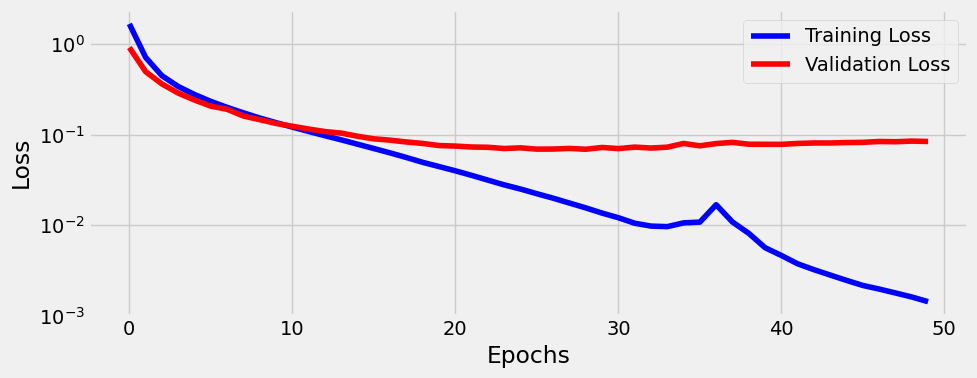

In [5]:
import matplotlib.pyplot as plt

plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_loss, label="Training Loss", c="b")
    plt.plot(val_loss, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()

In [7]:
import torchmetrics

accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
for _, (x, y) in enumerate(test_loader):
    x, y = x.to(device), y.to(device)
    yhat = model(x)
    accuracy(yhat, y)
accuracy.compute()
print(f"Test Accuracy: {accuracy.compute().item() * 100:.2f}%")

Test Accuracy: 98.19%
